随机森林训练集R2分数: 0.922
随机森林测试集R2分数: 0.927
随机森林训练集RMSE: 5.540
随机森林测试集RMSE: 5.642


,特征,重要性
0,2023人工智能专利申请数,0.309054
1,规模以上工业企业有效发明专利数（件）,0.111815
2,国内专利授权数,0.076143
3,国外技术引进合同数,0.073885
4,孵化器内企业总数,0.059831
5,按收发货人所在地分的进出口总额（亿万）,0.055432
6,规模以上工业企业专利申请数（件）,0.042461
7,规模以上工业企业R&D人员全时当量(人年),0.036461
8,规模以上工业企业新产品开发经费支出(万元),0.030645
9,人工智能创新发展试验区数量,0.029717


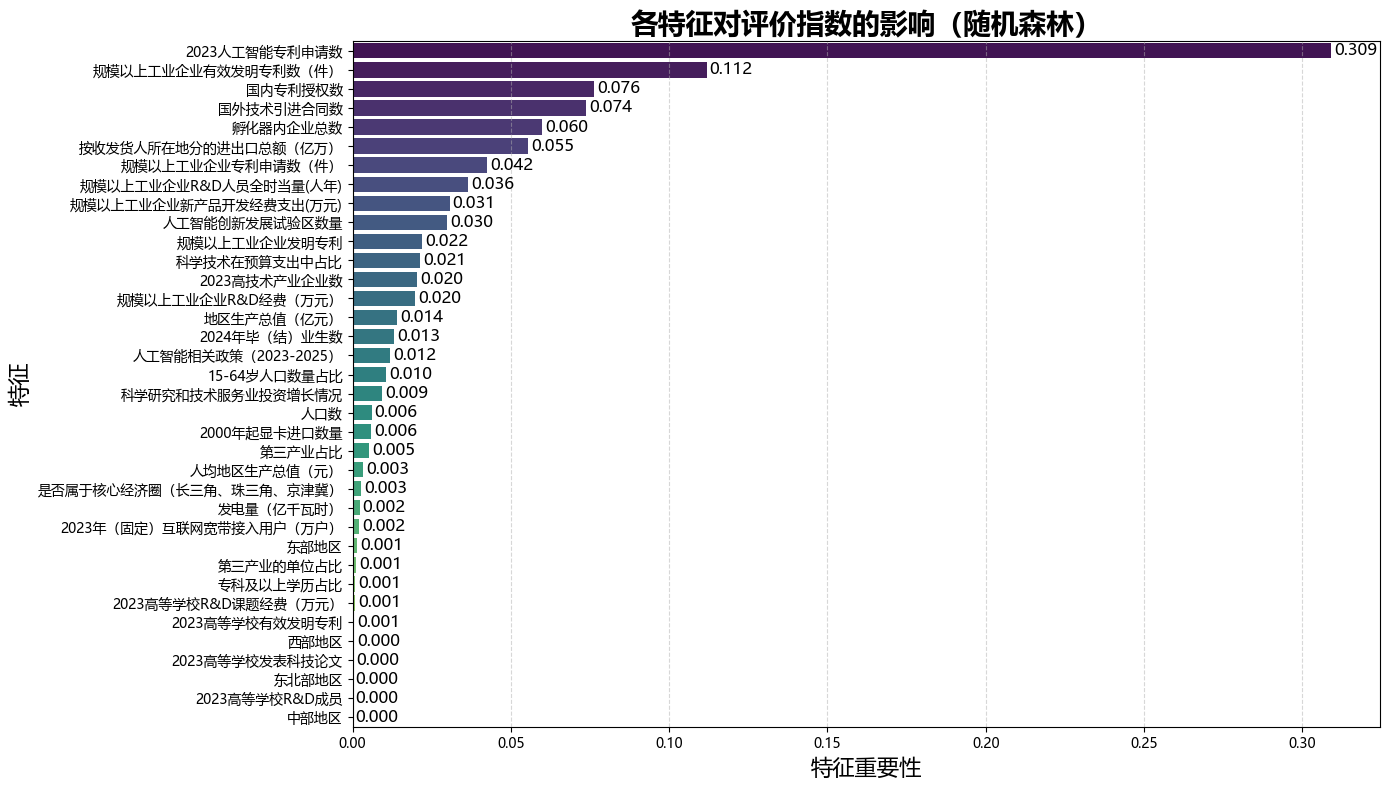

,特征,平均绝对SHAP值
35,2023人工智能专利申请数,5.392063
20,规模以上工业企业有效发明专利数（件）,1.864335
32,国外技术引进合同数,1.305084
22,国内专利授权数,1.095675
14,按收发货人所在地分的进出口总额（亿万）,0.995900
31,孵化器内企业总数,0.923817
18,规模以上工业企业专利申请数（件）,0.716833
21,规模以上工业企业新产品开发经费支出(万元),0.621710
16,规模以上工业企业R&D人员全时当量(人年),0.620998
34,人工智能创新发展试验区数量,0.589979


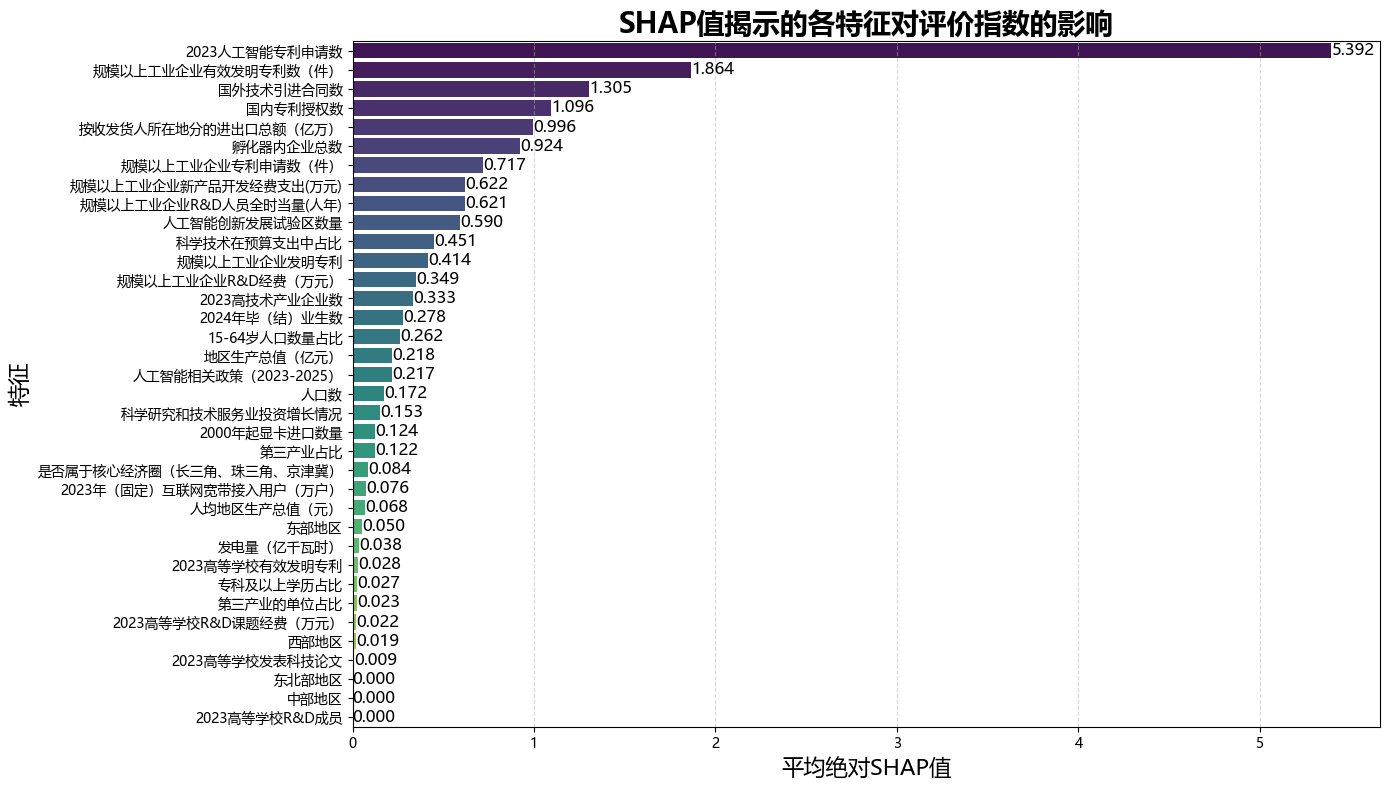

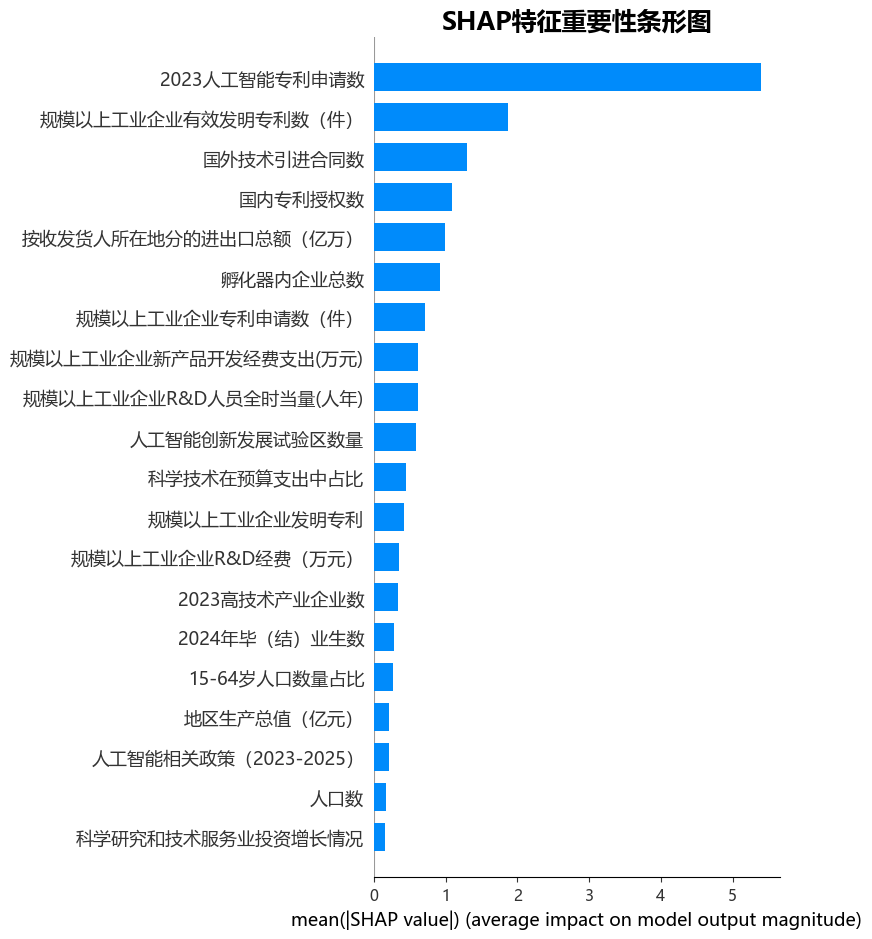

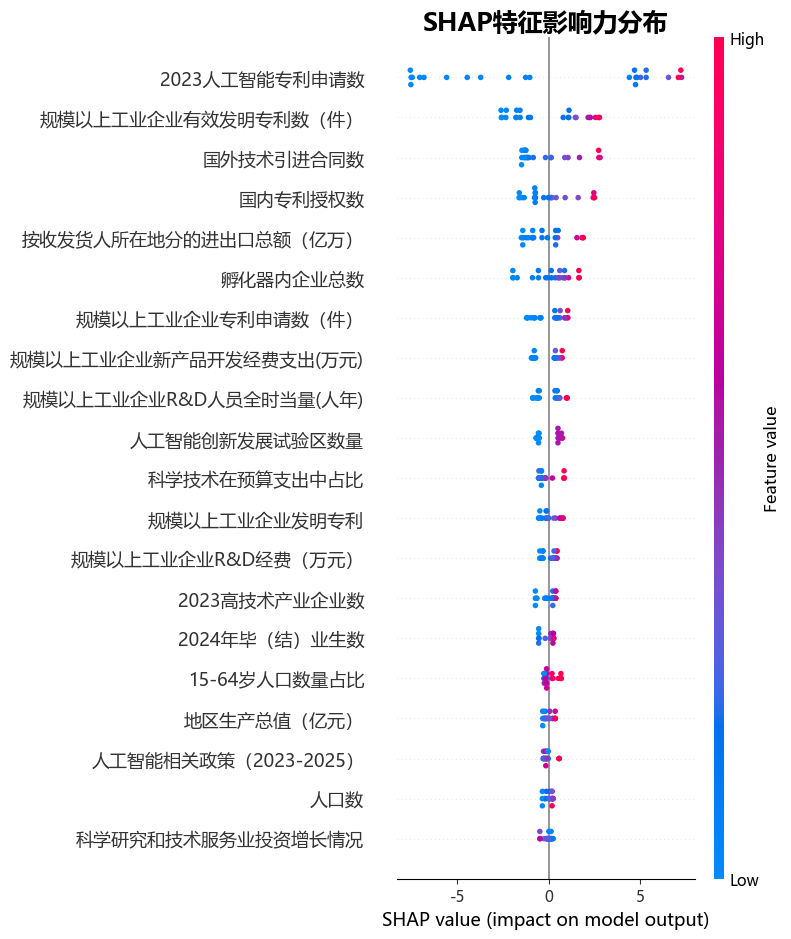

In [28]:
import pandas as pd
import numpy as np
import shap
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error
from IPython.display import display

import matplotlib.pyplot as plt

# 设置全局字体为微软雅黑
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False

# 读取数据
df = pd.read_csv('/home/mw/input/data_total74037403/地区角度数据集/地区.csv')

# 以评价指数为y，其它特征为x（去除省份和评价指数）
y = df['评价指数']
X = df.drop(['省份', '评价指数'], axis=1)

# 划分训练集和测试集（8:2）
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 随机森林建模（防止过拟合，适当调参）
rf = RandomForestRegressor(
    n_estimators=200,
    max_depth=5,
    min_samples_leaf=3,
    min_samples_split=4,
    random_state=42
)
rf.fit(X_train, y_train)

# 模型评估
y_pred_train = rf.predict(X_train)
y_pred_test = rf.predict(X_test)
r2_train = r2_score(y_train, y_pred_train)
r2_test = r2_score(y_test, y_pred_test)
rmse_train = mean_squared_error(y_train, y_pred_train, squared=False)
rmse_test = mean_squared_error(y_test, y_pred_test, squared=False)

print(f'随机森林训练集R2分数: {r2_train:.3f}')
print(f'随机森林测试集R2分数: {r2_test:.3f}')
print(f'随机森林训练集RMSE: {rmse_train:.3f}')
print(f'随机森林测试集RMSE: {rmse_test:.3f}')

# 特征重要性
importances = rf.feature_importances_
feature_names = X.columns
indices = importances.argsort()[::-1]

# 构建特征重要性DataFrame
import_df = pd.DataFrame({
    '特征': feature_names[indices],
    '重要性': importances[indices]
})

# 表格可视化
display(import_df.style.background_gradient(cmap='YlGnBu', subset=['重要性']).set_properties(**{'font-family': 'Microsoft YaHei'}))

plt.figure(figsize=(14, 8))
sns.barplot(
    x='重要性', y='特征', data=import_df,
    palette='viridis'
)
plt.title('各特征对评价指数的影响（随机森林）', fontsize=20, fontweight='bold')
plt.xlabel('特征重要性', fontsize=16)
plt.ylabel('特征', fontsize=16)
plt.grid(axis='x', linestyle='--', alpha=0.5)
for i, v in enumerate(import_df['重要性']):
    plt.text(v + 0.001, i, f"{v:.3f}", va='center', fontsize=12, color='black')
plt.tight_layout()
plt.show()

# SHAP分析
explainer = shap.TreeExplainer(rf)
shap_values = explainer.shap_values(X_train)

# 计算特征平均绝对SHAP值
shap_importance = pd.DataFrame({
    '特征': X.columns,
    '平均绝对SHAP值': np.abs(shap_values).mean(axis=0)
}).sort_values(by='平均绝对SHAP值', ascending=False)

# 表格可视化
display(shap_importance.style.background_gradient(cmap='YlGnBu', subset=['平均绝对SHAP值']).set_properties(**{'font-family': 'Microsoft YaHei'}))

# 复杂且漂亮的可视化
plt.figure(figsize=(14, 8))
sns.barplot(
    x='平均绝对SHAP值', y='特征', data=shap_importance,
    palette='viridis'
)
plt.title('SHAP值揭示的各特征对评价指数的影响', fontsize=20, fontweight='bold')
plt.xlabel('平均绝对SHAP值', fontsize=16)
plt.ylabel('特征', fontsize=16)
plt.grid(axis='x', linestyle='--', alpha=0.5)
for i, v in enumerate(shap_importance['平均绝对SHAP值']):
    plt.text(v + 0.001, i, f"{v:.3f}", va='center', fontsize=12, color='black')
plt.tight_layout()
plt.show()

# SHAP summary plot
shap.initjs()
plt.figure(figsize=(12, 8))
shap.summary_plot(shap_values, X_train, plot_type="bar", show=False, color_bar=True)
plt.title('SHAP特征重要性条形图', fontsize=18, fontweight='bold', fontname='Microsoft YaHei')
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 8))
shap.summary_plot(shap_values, X_train, show=False)
plt.title('SHAP特征影响力分布', fontsize=18, fontweight='bold', fontname='Microsoft YaHei')
plt.tight_layout()
plt.show()

岭回归训练集R2分数: 0.991
岭回归测试集R2分数: 0.795
岭回归训练集RMSE: 1.924
岭回归测试集RMSE: 9.443
最佳alpha: 1.0


,特征,系数
9,人均地区生产总值（元）,5.864083
23,2024年毕（结）业生数,5.685931
11,科学技术在预算支出中占比,4.417351
33,2000年起显卡进口数量,3.547129
34,人工智能创新发展试验区数量,3.538473
30,人工智能相关政策（2023-2025）,-2.819786
3,专科及以上学历占比,2.734535
8,地区生产总值（亿元）,2.649570
28,2023年（固定）互联网宽带接入用户（万户）,2.603426
20,规模以上工业企业有效发明专利数（件）,-2.218061


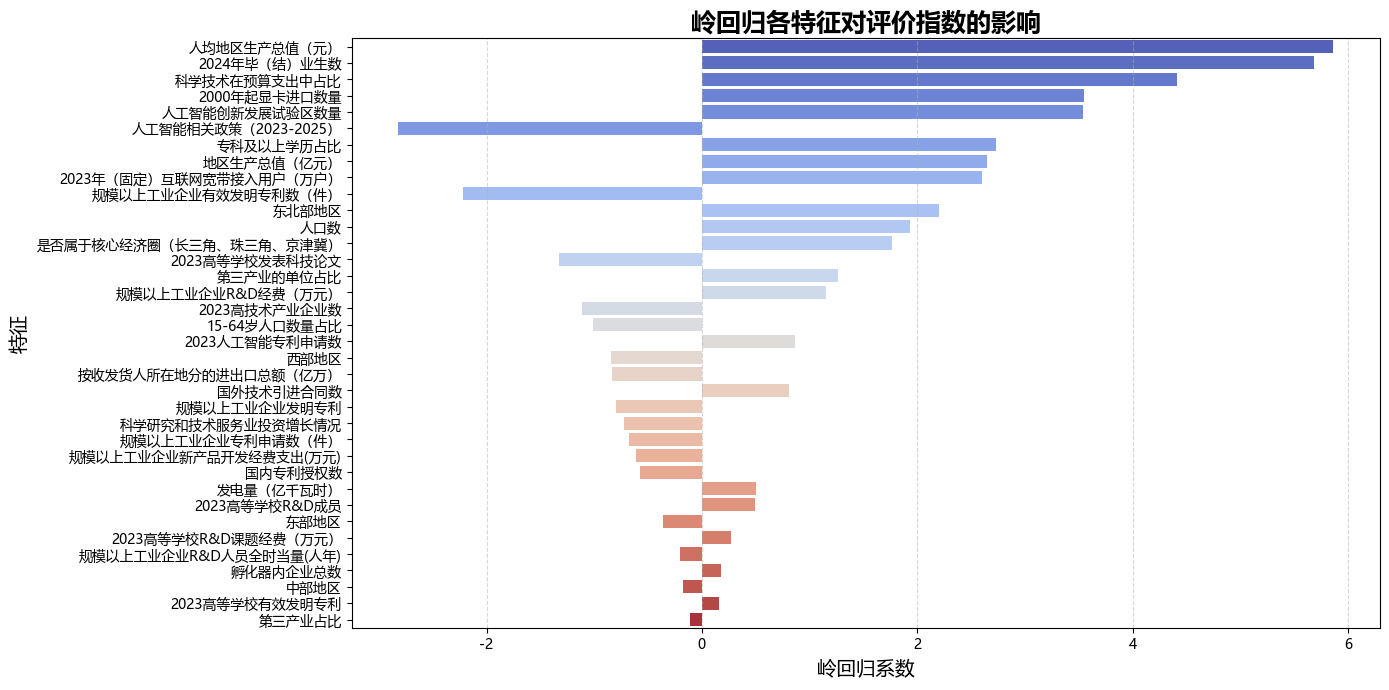

,特征,平均绝对SHAP值
35,2023人工智能专利申请数,5.392063
20,规模以上工业企业有效发明专利数（件）,1.864335
32,国外技术引进合同数,1.305084
22,国内专利授权数,1.095675
14,按收发货人所在地分的进出口总额（亿万）,0.995900
31,孵化器内企业总数,0.923817
18,规模以上工业企业专利申请数（件）,0.716833
21,规模以上工业企业新产品开发经费支出(万元),0.621710
16,规模以上工业企业R&D人员全时当量(人年),0.620998
34,人工智能创新发展试验区数量,0.589979


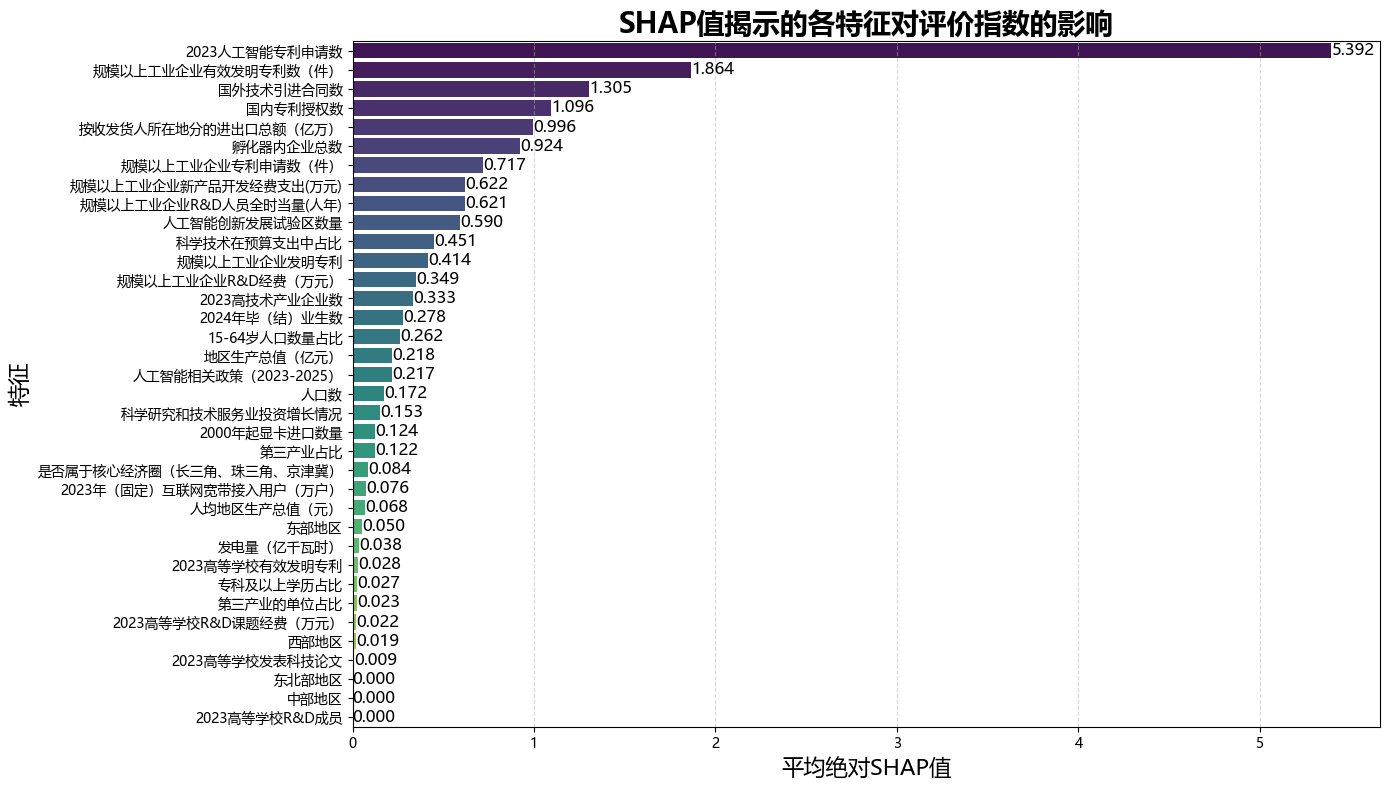

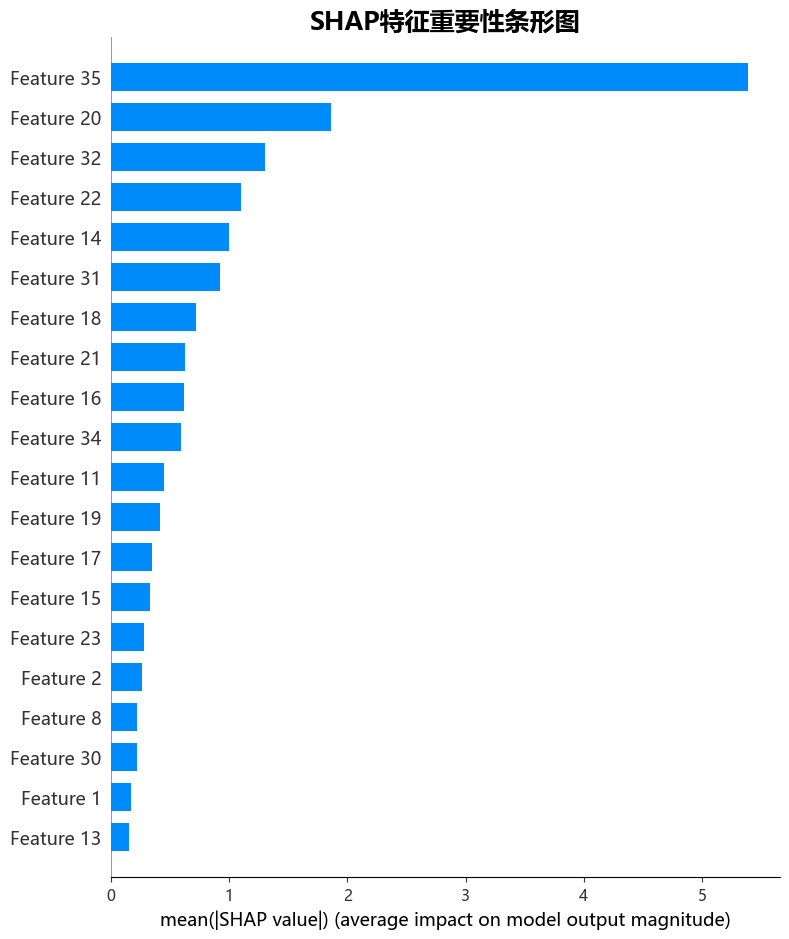

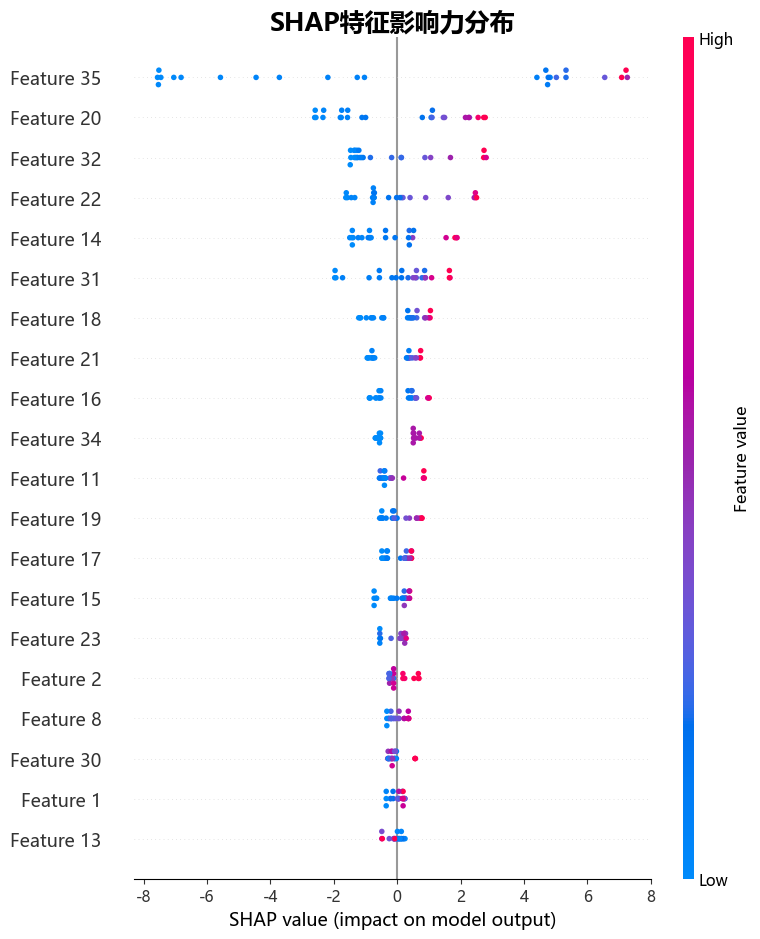

In [27]:
import pandas as pd
import numpy as np
import shap
import seaborn as sns
from sklearn.linear_model import RidgeCV
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error
from IPython.display import display
from sklearn.ensemble import RandomForestRegressor

import matplotlib.pyplot as plt

# 设置全局字体为微软雅黑
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False

# 读取数据
df = pd.read_csv('/home/mw/input/data_total74037403/地区角度数据集/地区.csv')

# 以评价指数为y，其它特征为x（去除省份和评价指数）
y = df['评价指数']
X = df.drop(['省份', '评价指数'], axis=1)

# 标准化特征
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 划分训练集和测试集（8:2）
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

# 岭回归，交叉验证自动选择最佳alpha，防止过拟合
alphas = [0.01, 0.1, 1, 10, 100]
ridge = RidgeCV(alphas=alphas, cv=5)
ridge.fit(X_train, y_train)

# 模型评估
y_pred_train = ridge.predict(X_train)
y_pred_test = ridge.predict(X_test)
r2_train = r2_score(y_train, y_pred_train)
r2_test = r2_score(y_test, y_pred_test)
rmse_train = mean_squared_error(y_train, y_pred_train, squared=False)
rmse_test = mean_squared_error(y_test, y_pred_test, squared=False)

print(f'岭回归训练集R2分数: {r2_train:.3f}')
print(f'岭回归测试集R2分数: {r2_test:.3f}')
print(f'岭回归训练集RMSE: {rmse_train:.3f}')
print(f'岭回归测试集RMSE: {rmse_test:.3f}')
print(f'最佳alpha: {ridge.alpha_}')

# 系数与特征名对应
coef_df = pd.DataFrame({
    '特征': X.columns,
    '系数': ridge.coef_
}).sort_values(by='系数', key=abs, ascending=False)

# 表格展示
display(coef_df.style.background_gradient(cmap='coolwarm', subset=['系数']).set_properties(**{'font-family': 'Microsoft YaHei'}))

# 可视化
plt.figure(figsize=(14, 7))
sns.barplot(
    x='系数', y='特征', data=coef_df,
    palette=sns.color_palette("coolwarm", n_colors=len(coef_df)),
    orient='h'
)
plt.title('岭回归各特征对评价指数的影响', fontsize=18, fontweight='bold')
plt.xlabel('岭回归系数', fontsize=14)
plt.ylabel('特征', fontsize=14)
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# 用随机森林做SHAP分析（树模型，适合全局解释）
rf = RandomForestRegressor(
    n_estimators=200,
    max_depth=5,
    min_samples_leaf=3,
    min_samples_split=4,
    random_state=42
)
rf.fit(X_train, y_train)
explainer = shap.TreeExplainer(rf)
shap_values = explainer.shap_values(X_train)

# 计算特征平均绝对SHAP值
shap_importance = pd.DataFrame({
    '特征': X.columns,
    '平均绝对SHAP值': np.abs(shap_values).mean(axis=0)
}).sort_values(by='平均绝对SHAP值', ascending=False)

# 表格可视化
display(shap_importance.style.background_gradient(cmap='YlGnBu', subset=['平均绝对SHAP值']).set_properties(**{'font-family': 'Microsoft YaHei'}))

plt.figure(figsize=(14, 8))
sns.barplot(
    x='平均绝对SHAP值', y='特征', data=shap_importance,
    palette='viridis'
)
plt.title('SHAP值揭示的各特征对评价指数的影响', fontsize=20, fontweight='bold')
plt.xlabel('平均绝对SHAP值', fontsize=16)
plt.ylabel('特征', fontsize=16)
plt.grid(axis='x', linestyle='--', alpha=0.5)
for i, v in enumerate(shap_importance['平均绝对SHAP值']):
    plt.text(v + 0.001, i, f"{v:.3f}", va='center', fontsize=12, color='black')
plt.tight_layout()
plt.show()

# SHAP summary plot（更复杂的全局解释图）
shap.initjs()
plt.figure(figsize=(12, 8))
shap.summary_plot(shap_values, X_train, plot_type="bar", show=False, color_bar=True)
plt.title('SHAP特征重要性条形图', fontsize=18, fontweight='bold', fontname='Microsoft YaHei')
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 8))
shap.summary_plot(shap_values, X_train, show=False)
plt.title('SHAP特征影响力分布', fontsize=18, fontweight='bold', fontname='Microsoft YaHei')
plt.tight_layout()
plt.show()

Lasso训练集R2分数: 0.962
Lasso测试集R2分数: 0.826
Lasso训练集RMSE: 3.841
Lasso测试集RMSE: 8.695
最佳alpha: 1.0


,特征,系数
23,2024年毕（结）业生数,9.605390
9,人均地区生产总值（元）,6.864666
34,人工智能创新发展试验区数量,4.227309
11,科学技术在预算支出中占比,2.794633
29,是否属于核心经济圈（长三角、珠三角、京津冀）,1.494748
0,第三产业的单位占比,1.428784
27,东北部地区,1.397042
13,科学研究和技术服务业投资增长情况,-0.400985
10,第三产业占比,0.146204
7,2023高等学校有效发明专利,0.118682


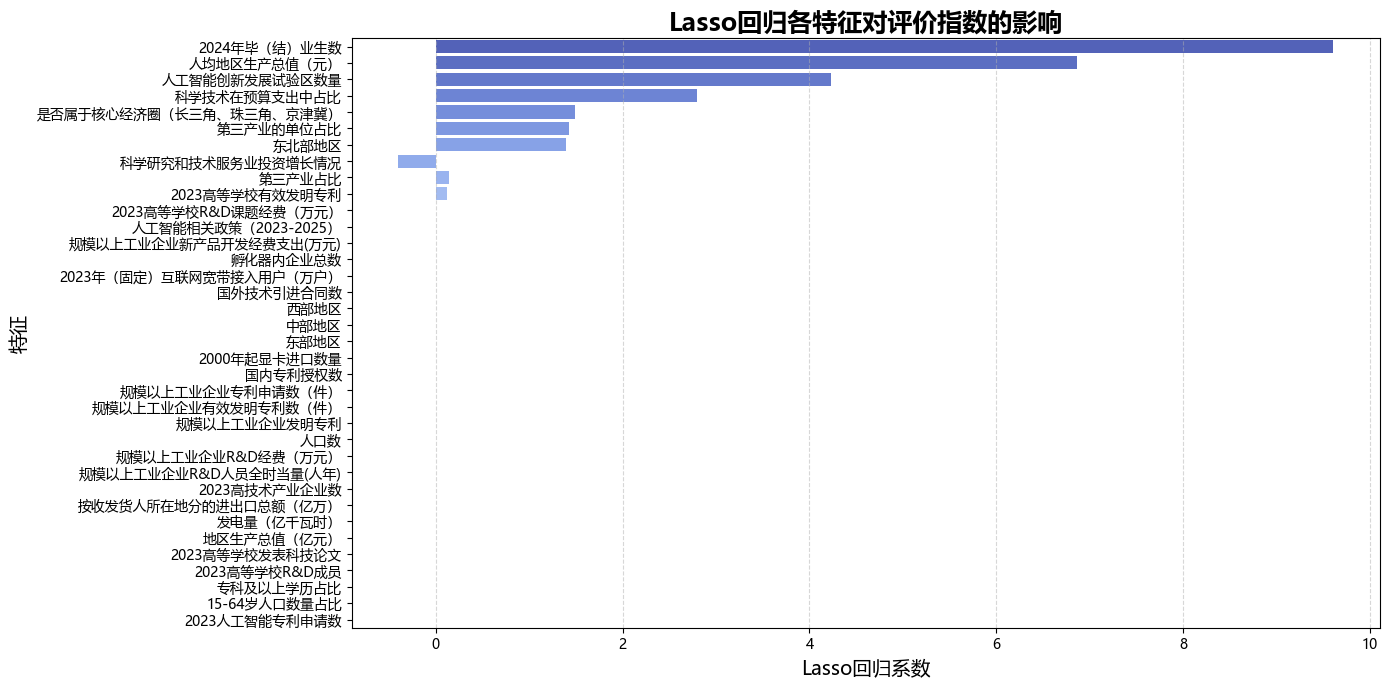

,特征,平均绝对SHAP值
35,2023人工智能专利申请数,5.392063
20,规模以上工业企业有效发明专利数（件）,1.864335
32,国外技术引进合同数,1.305084
22,国内专利授权数,1.095675
14,按收发货人所在地分的进出口总额（亿万）,0.995900
31,孵化器内企业总数,0.923817
18,规模以上工业企业专利申请数（件）,0.716833
21,规模以上工业企业新产品开发经费支出(万元),0.621710
16,规模以上工业企业R&D人员全时当量(人年),0.620998
34,人工智能创新发展试验区数量,0.589979


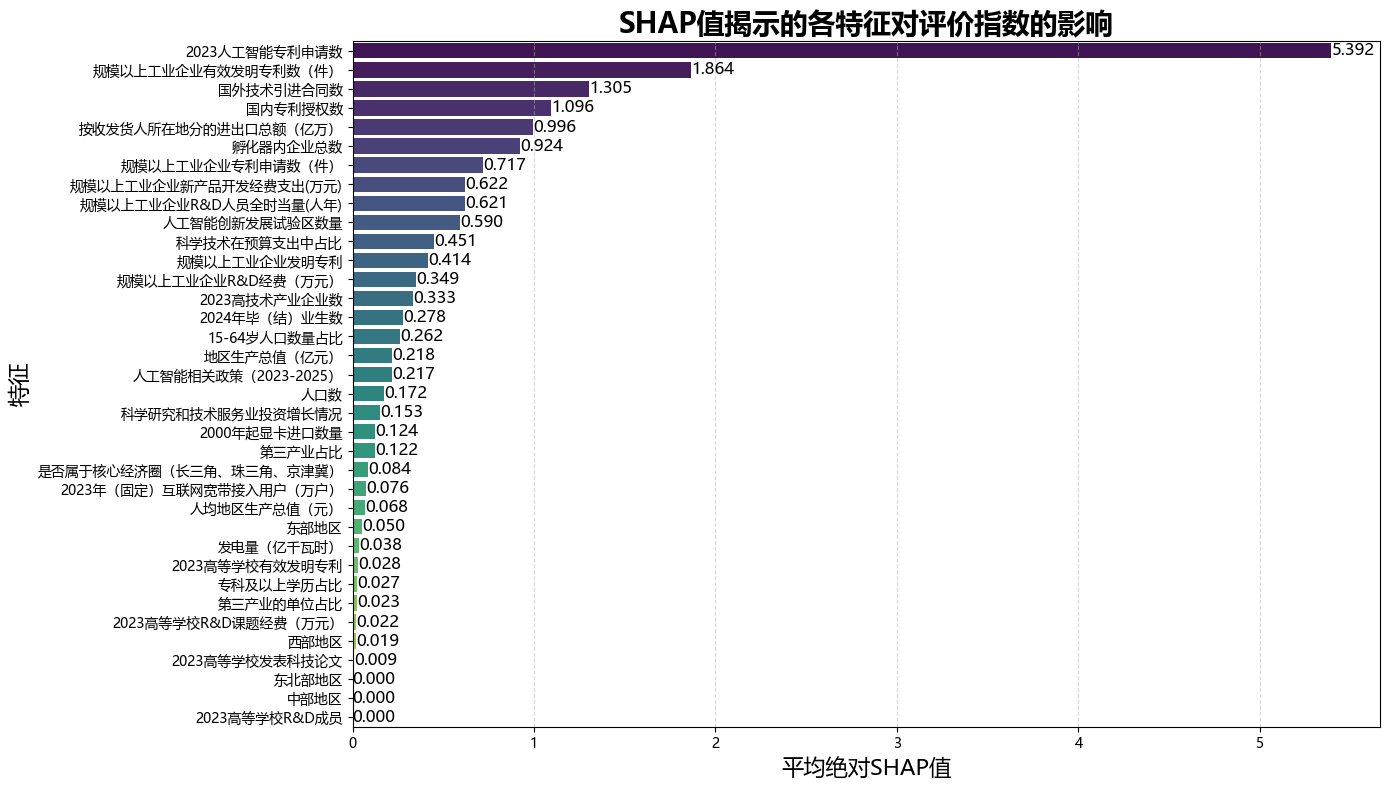

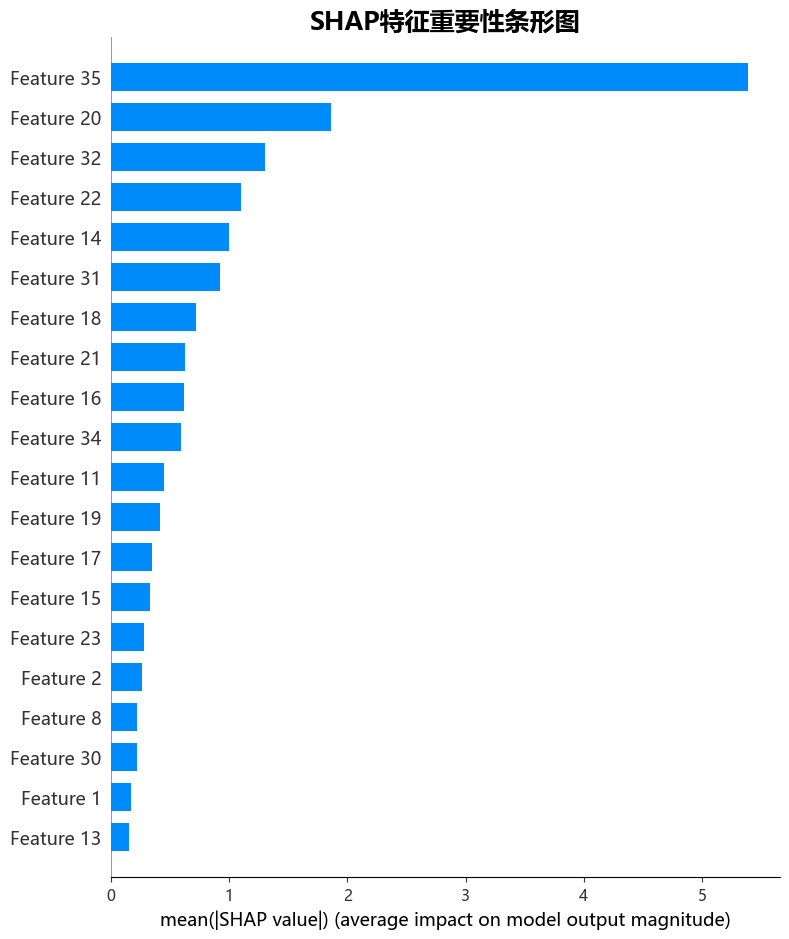

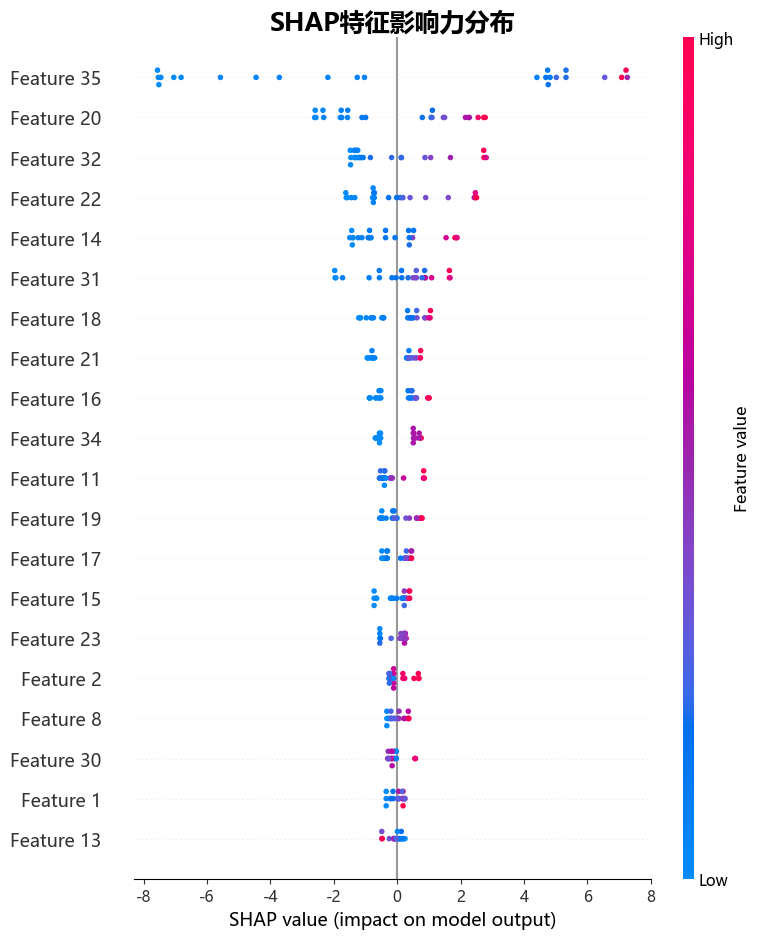

In [30]:
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.linear_model import LassoCV
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error
from IPython.display import display
import matplotlib.pyplot as plt
import shap

# 设置全局字体为微软雅黑
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False

# 读取数据
df = pd.read_csv('/home/mw/input/data_total74037403/地区角度数据集/地区.csv')

# 以评价指数为y，其它特征为x（去除省份和评价指数）
y = df['评价指数']
X = df.drop(['省份', '评价指数'], axis=1)

# 标准化特征
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 划分训练集和测试集（8:2）
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

# Lasso回归，交叉验证自动选择最佳alpha，防止过拟合
alphas = [0.001, 0.01, 0.1, 1, 10, 100]
lasso = LassoCV(alphas=alphas, cv=5, max_iter=10000, random_state=42)
lasso.fit(X_train, y_train)

# 模型评估
y_pred_train = lasso.predict(X_train)
y_pred_test = lasso.predict(X_test)
r2_train = r2_score(y_train, y_pred_train)
r2_test = r2_score(y_test, y_pred_test)
rmse_train = mean_squared_error(y_train, y_pred_train, squared=False)
rmse_test = mean_squared_error(y_test, y_pred_test, squared=False)

print(f'Lasso训练集R2分数: {r2_train:.3f}')
print(f'Lasso测试集R2分数: {r2_test:.3f}')
print(f'Lasso训练集RMSE: {rmse_train:.3f}')
print(f'Lasso测试集RMSE: {rmse_test:.3f}')
print(f'最佳alpha: {lasso.alpha_}')

# 系数与特征名对应
coef_df = pd.DataFrame({
    '特征': X.columns,
    '系数': lasso.coef_
}).sort_values(by='系数', key=abs, ascending=False)

# 表格展示
display(coef_df.style.background_gradient(cmap='coolwarm', subset=['系数']).set_properties(**{'font-family': 'Microsoft YaHei'}))

# 可视化
plt.figure(figsize=(14, 7))
sns.barplot(
    x='系数', y='特征', data=coef_df,
    palette=sns.color_palette("coolwarm", n_colors=len(coef_df)),
    orient='h'
)
plt.title('Lasso回归各特征对评价指数的影响', fontsize=18, fontweight='bold')
plt.xlabel('Lasso回归系数', fontsize=14)
plt.ylabel('特征', fontsize=14)
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# 用树模型做SHAP分析
from sklearn.ensemble import RandomForestRegressor
rf = RandomForestRegressor(
    n_estimators=200,
    max_depth=5,
    min_samples_leaf=3,
    min_samples_split=4,
    random_state=42
)
rf.fit(X_train, y_train)
explainer = shap.TreeExplainer(rf)
shap_values = explainer.shap_values(X_train)

# 计算特征平均绝对SHAP值
shap_importance = pd.DataFrame({
    '特征': X.columns,
    '平均绝对SHAP值': np.abs(shap_values).mean(axis=0)
}).sort_values(by='平均绝对SHAP值', ascending=False)

# SHAP表格可视化
display(shap_importance.style.background_gradient(cmap='YlGnBu', subset=['平均绝对SHAP值']).set_properties(**{'font-family': 'Microsoft YaHei'}))

# SHAP条形图
plt.figure(figsize=(14, 8))
sns.barplot(
    x='平均绝对SHAP值', y='特征', data=shap_importance,
    palette='viridis'
)
plt.title('SHAP值揭示的各特征对评价指数的影响', fontsize=20, fontweight='bold')
plt.xlabel('平均绝对SHAP值', fontsize=16)
plt.ylabel('特征', fontsize=16)
plt.grid(axis='x', linestyle='--', alpha=0.5)
for i, v in enumerate(shap_importance['平均绝对SHAP值']):
    plt.text(v + 0.001, i, f"{v:.3f}", va='center', fontsize=12, color='black')
plt.tight_layout()
plt.show()

# SHAP summary plot（全局解释图）
shap.initjs()
plt.figure(figsize=(12, 8))
shap.summary_plot(shap_values, X_train, plot_type="bar", show=False, color_bar=True)
plt.title('SHAP特征重要性条形图', fontsize=18, fontweight='bold', fontname='Microsoft YaHei')
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 8))
shap.summary_plot(shap_values, X_train, show=False)
plt.title('SHAP特征影响力分布', fontsize=18, fontweight='bold', fontname='Microsoft YaHei')
plt.tight_layout()
plt.show()

XGBoost训练集R2分数: 1.000
XGBoost测试集R2分数: 0.887
XGBoost训练集RMSE: 0.313
XGBoost测试集RMSE: 7.002


,特征,重要性
0,规模以上工业企业R&D人员全时当量(人年),0.326607
1,规模以上工业企业R&D经费（万元）,0.199020
2,2023人工智能专利申请数,0.122278
3,规模以上工业企业发明专利,0.055316
4,地区生产总值（亿元）,0.051800
5,国内专利授权数,0.039109
6,孵化器内企业总数,0.034939
7,按收发货人所在地分的进出口总额（亿万）,0.030600
8,2023年（固定）互联网宽带接入用户（万户）,0.026032
9,科学技术在预算支出中占比,0.019074


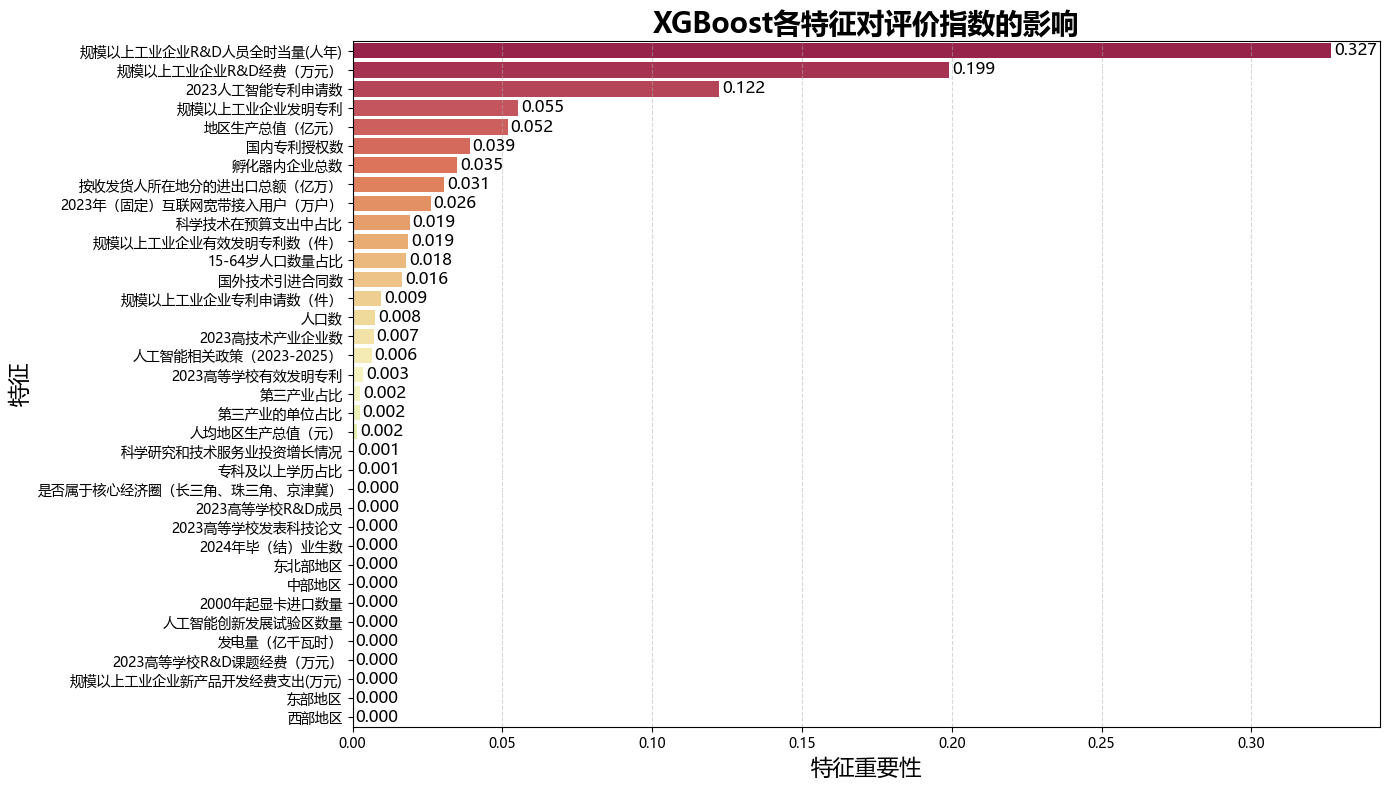

,特征,平均绝对SHAP值
35,2023人工智能专利申请数,7.894748
2,15-64岁人口数量占比,2.675239
16,规模以上工业企业R&D人员全时当量(人年),2.619431
14,按收发货人所在地分的进出口总额（亿万）,1.268818
1,人口数,1.235354
8,地区生产总值（亿元）,1.149028
31,孵化器内企业总数,0.875928
0,第三产业的单位占比,0.822093
11,科学技术在预算支出中占比,0.797401
22,国内专利授权数,0.747107


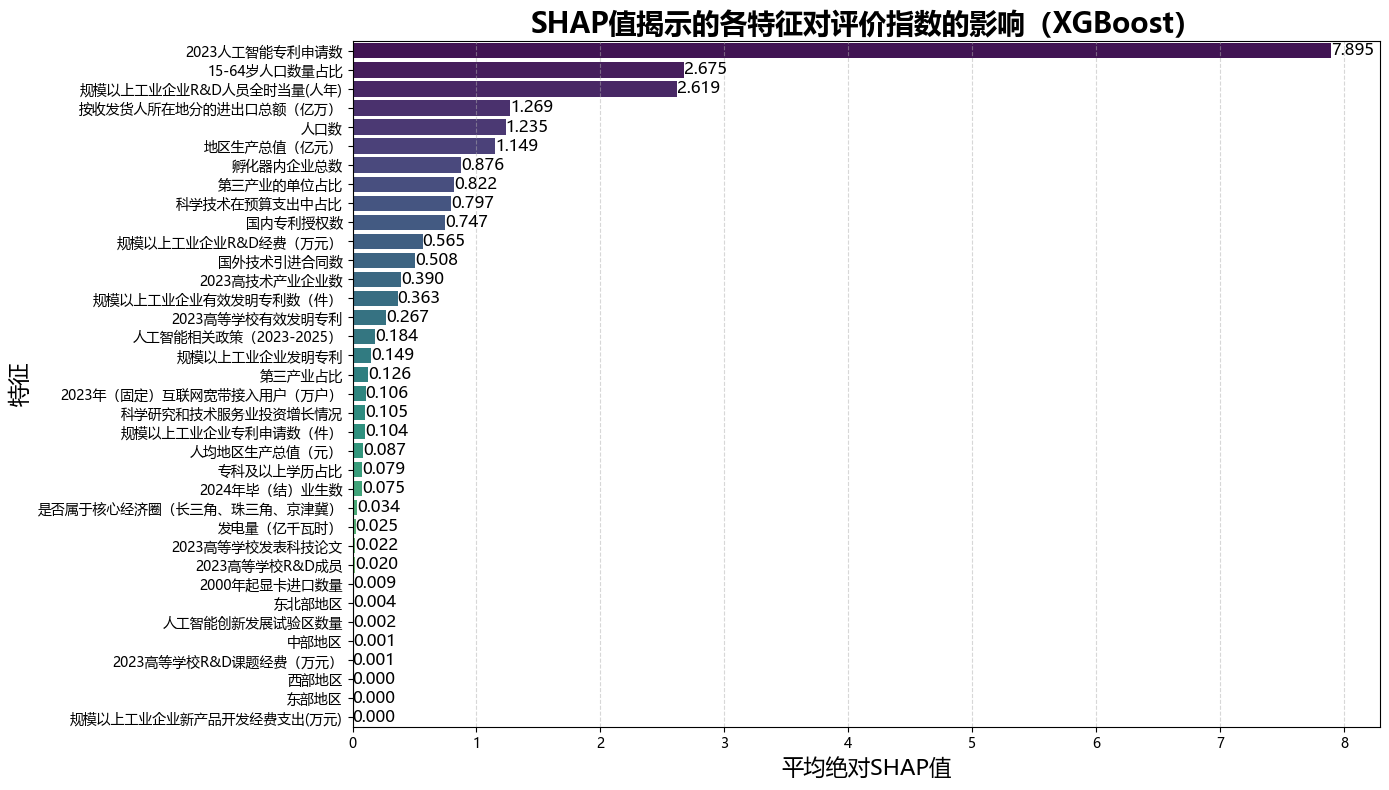

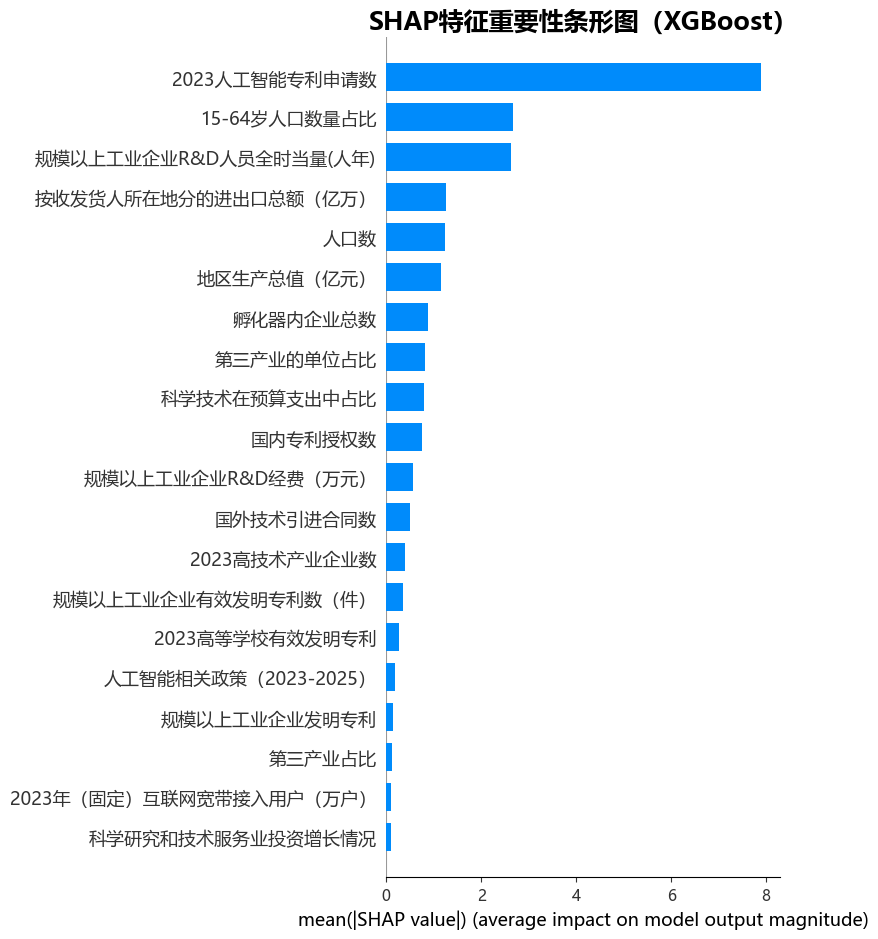

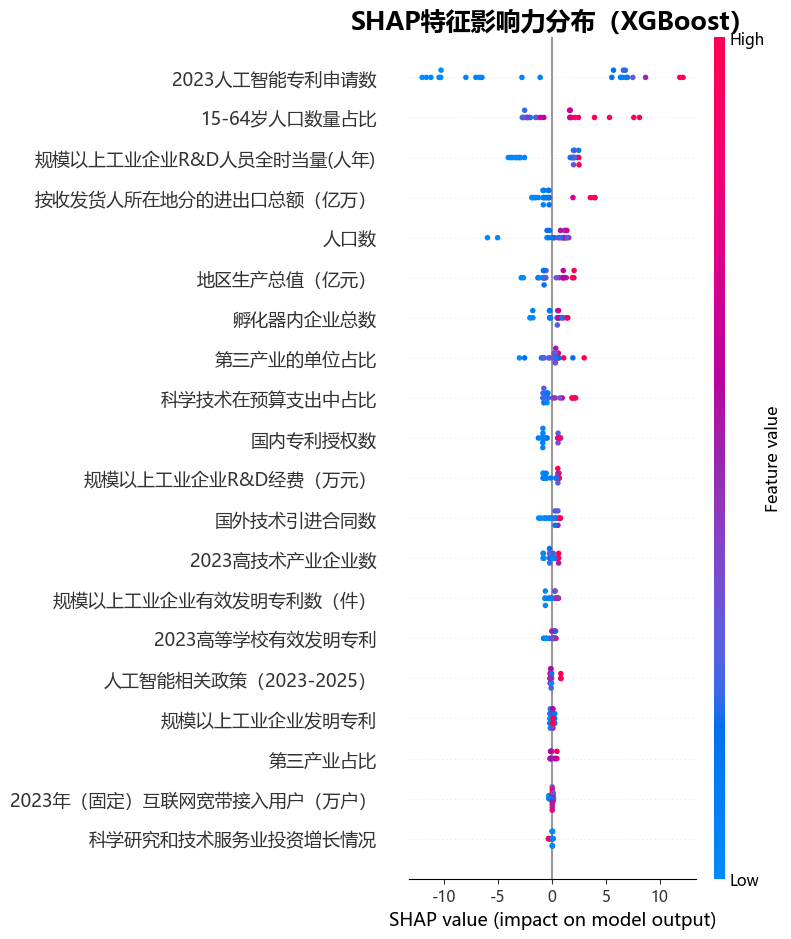

In [29]:
import xgboost as xgb
import shap
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error
from IPython.display import display
import matplotlib.pyplot as plt

# 设置全局字体为微软雅黑
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False

# 读取数据
df = pd.read_csv('/home/mw/input/data_total74037403/地区角度数据集/地区.csv')

# 以评价指数为y，其它特征为x（去除省份和评价指数）
y = df['评价指数']
X = df.drop(['省份', '评价指数'], axis=1)

# 划分训练集和测试集（8:2）
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# XGBoost建模，防止过拟合，适当调参
xgb_reg = xgb.XGBRegressor(
    n_estimators=300,
    max_depth=3,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=1,
    reg_lambda=1,
    random_state=42
)
xgb_reg.fit(X_train, y_train)

# 模型评估
y_pred_train = xgb_reg.predict(X_train)
y_pred_test = xgb_reg.predict(X_test)
r2_train = r2_score(y_train, y_pred_train)
r2_test = r2_score(y_test, y_pred_test)
rmse_train = mean_squared_error(y_train, y_pred_train, squared=False)
rmse_test = mean_squared_error(y_test, y_pred_test, squared=False)

print(f'XGBoost训练集R2分数: {r2_train:.3f}')
print(f'XGBoost测试集R2分数: {r2_test:.3f}')
print(f'XGBoost训练集RMSE: {rmse_train:.3f}')
print(f'XGBoost测试集RMSE: {rmse_test:.3f}')

# 特征重要性
importances_xgb = xgb_reg.feature_importances_
feature_names = X.columns
indices_xgb = importances_xgb.argsort()[::-1]

# 构建特征重要性DataFrame
import_df_xgb = pd.DataFrame({
    '特征': feature_names[indices_xgb],
    '重要性': importances_xgb[indices_xgb]
})

# 表格可视化
display(import_df_xgb.style.background_gradient(cmap='YlOrRd', subset=['重要性']).set_properties(**{'font-family': 'Microsoft YaHei'}))

plt.figure(figsize=(14, 8))
sns.barplot(
    x='重要性', y='特征', data=import_df_xgb,
    palette='Spectral'
)
plt.title('XGBoost各特征对评价指数的影响', fontsize=20, fontweight='bold')
plt.xlabel('特征重要性', fontsize=16)
plt.ylabel('特征', fontsize=16)
plt.grid(axis='x', linestyle='--', alpha=0.5)
for i, v in enumerate(import_df_xgb['重要性']):
    plt.text(v + 0.001, i, f"{v:.3f}", va='center', fontsize=12, color='black')
plt.tight_layout()
plt.show()

# 基于树的SHAP值分析
explainer = shap.TreeExplainer(xgb_reg)
shap_values = explainer.shap_values(X_train)

shap_importance_xgb = pd.DataFrame({
    '特征': X.columns,
    '平均绝对SHAP值': np.abs(shap_values).mean(axis=0)
}).sort_values(by='平均绝对SHAP值', ascending=False)

# SHAP表格可视化
display(shap_importance_xgb.style.background_gradient(cmap='YlGnBu', subset=['平均绝对SHAP值']).set_properties(**{'font-family': 'Microsoft YaHei'}))

# SHAP条形图
plt.figure(figsize=(14, 8))
sns.barplot(
    x='平均绝对SHAP值', y='特征', data=shap_importance_xgb,
    palette='viridis'
)
plt.title('SHAP值揭示的各特征对评价指数的影响（XGBoost）', fontsize=20, fontweight='bold')
plt.xlabel('平均绝对SHAP值', fontsize=16)
plt.ylabel('特征', fontsize=16)
plt.grid(axis='x', linestyle='--', alpha=0.5)
for i, v in enumerate(shap_importance_xgb['平均绝对SHAP值']):
    plt.text(v + 0.001, i, f"{v:.3f}", va='center', fontsize=12, color='black')
plt.tight_layout()
plt.show()

# SHAP summary plot（全局解释图）
shap.initjs()
plt.figure(figsize=(12, 8))
shap.summary_plot(shap_values, X_train, plot_type="bar", show=False, color_bar=True)
plt.title('SHAP特征重要性条形图（XGBoost）', fontsize=18, fontweight='bold', fontname='Microsoft YaHei')
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 8))
shap.summary_plot(shap_values, X_train, show=False)
plt.title('SHAP特征影响力分布（XGBoost）', fontsize=18, fontweight='bold', fontname='Microsoft YaHei')
plt.tight_layout()
plt.show()

PCA+线性回归训练集R2分数: 0.921
PCA+线性回归测试集R2分数: 0.864
PCA+线性回归训练集RMSE: 5.559
PCA+线性回归测试集RMSE: 7.702


,特征,PCA贡献度
2023人工智能专利申请数,2023人工智能专利申请数,0.159302
人口数,人口数,0.154609
科学技术在预算支出中占比,科学技术在预算支出中占比,0.149776
发电量（亿千瓦时）,发电量（亿千瓦时）,0.147925
2023年（固定）互联网宽带接入用户（万户）,2023年（固定）互联网宽带接入用户（万户）,0.147162
东部地区,东部地区,0.146526
规模以上工业企业有效发明专利数（件）,规模以上工业企业有效发明专利数（件）,0.140859
西部地区,西部地区,0.140543
规模以上工业企业发明专利,规模以上工业企业发明专利,0.139674
人工智能创新发展试验区数量,人工智能创新发展试验区数量,0.139001


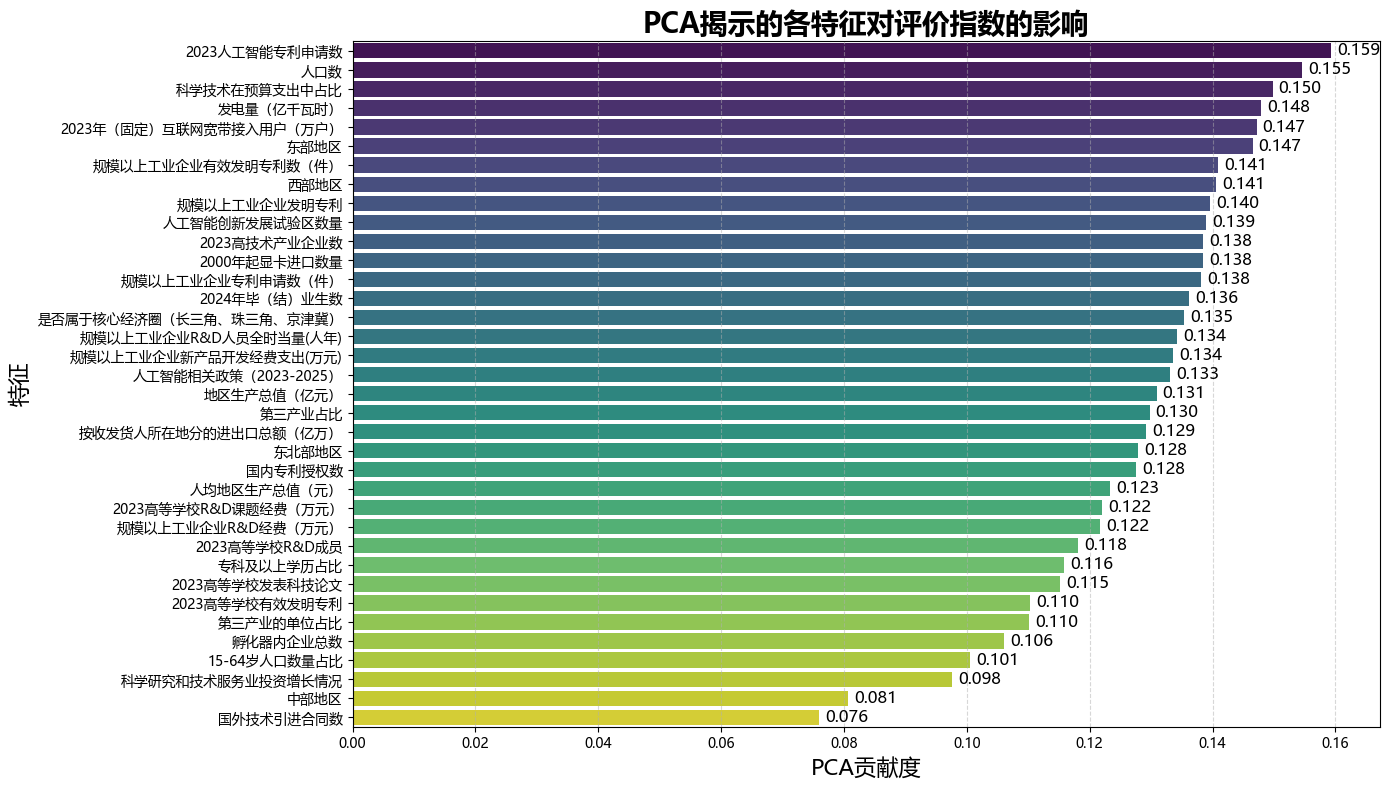

,特征,平均绝对SHAP值
35,2023人工智能专利申请数,5.392063
20,规模以上工业企业有效发明专利数（件）,1.864335
32,国外技术引进合同数,1.305084
22,国内专利授权数,1.095675
14,按收发货人所在地分的进出口总额（亿万）,0.995900
31,孵化器内企业总数,0.923817
18,规模以上工业企业专利申请数（件）,0.716833
21,规模以上工业企业新产品开发经费支出(万元),0.621710
16,规模以上工业企业R&D人员全时当量(人年),0.620998
34,人工智能创新发展试验区数量,0.589979


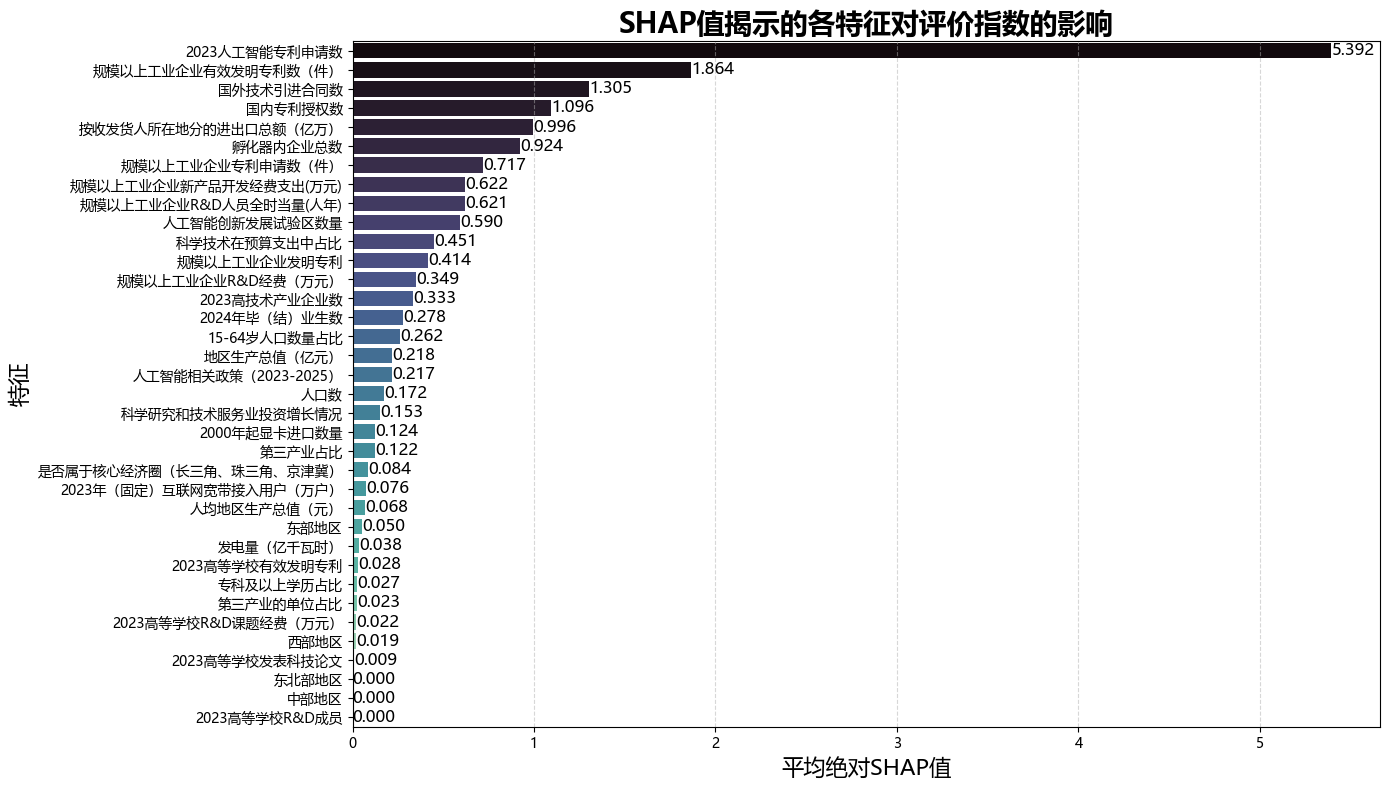

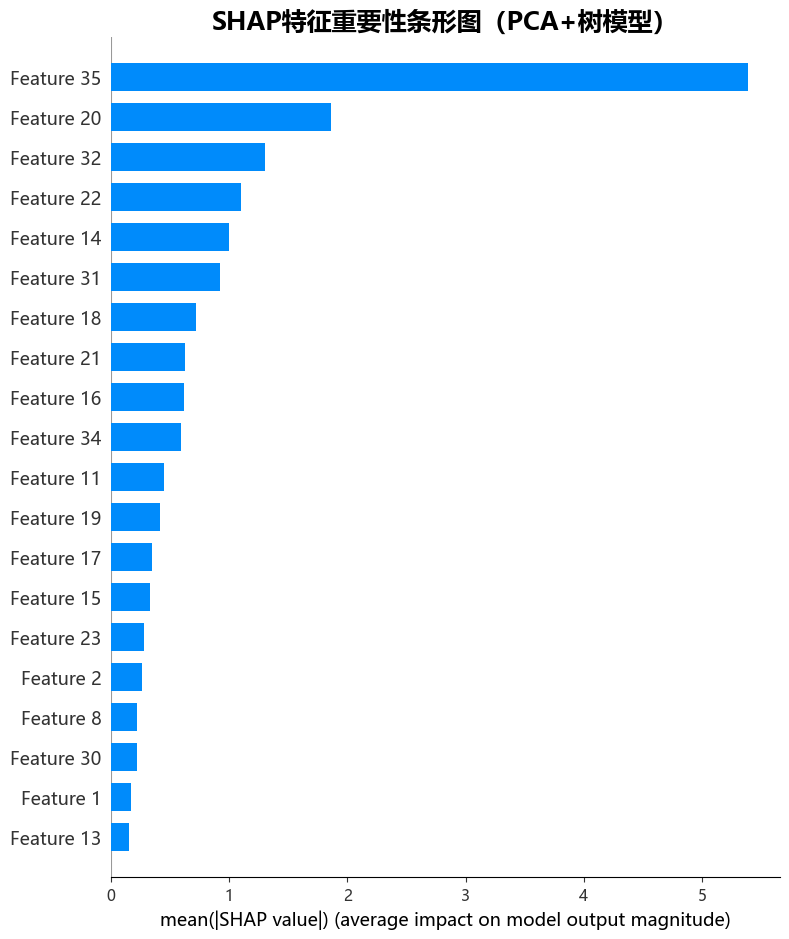

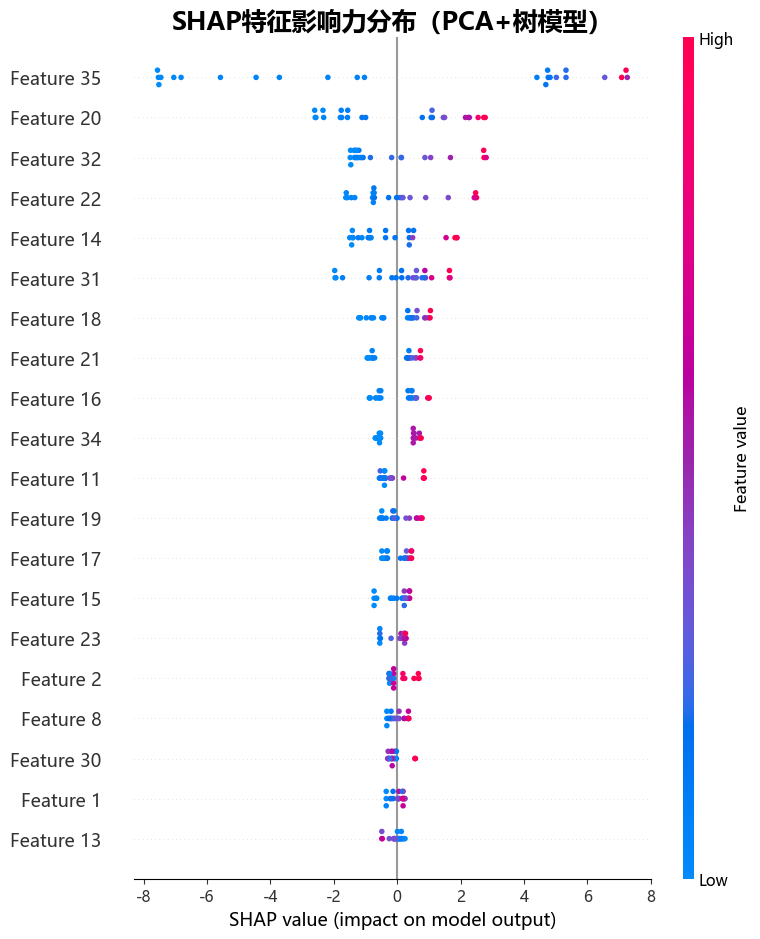

In [31]:
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
from IPython.display import display
import shap
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor

import matplotlib.pyplot as plt

# 设置全局字体为微软雅黑
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False

# 读取数据
df = pd.read_csv('/home/mw/input/data_total74037403/地区角度数据集/地区.csv')

# 以评价指数为y，其它特征为x（去除省份和评价指数）
y = df['评价指数']
X = df.drop(['省份', '评价指数'], axis=1)

# 标准化
scaler_pca = StandardScaler()
X_scaled = scaler_pca.fit_transform(X)

# 划分训练集和测试集（8:2）
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

# PCA降维，保留95%方差
pca = PCA(n_components=0.95, random_state=42)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

# 用线性回归拟合PCA主成分
lr = LinearRegression()
lr.fit(X_train_pca, y_train)
y_pred_train = lr.predict(X_train_pca)
y_pred_test = lr.predict(X_test_pca)

# 评估
r2_train = r2_score(y_train, y_pred_train)
r2_test = r2_score(y_test, y_pred_test)
rmse_train = mean_squared_error(y_train, y_pred_train, squared=False)
rmse_test = mean_squared_error(y_test, y_pred_test, squared=False)

print(f'PCA+线性回归训练集R2分数: {r2_train:.3f}')
print(f'PCA+线性回归测试集R2分数: {r2_test:.3f}')
print(f'PCA+线性回归训练集RMSE: {rmse_train:.3f}')
print(f'PCA+线性回归测试集RMSE: {rmse_test:.3f}')

# 主成分贡献
loadings = pd.DataFrame(pca.components_.T, index=X.columns, columns=[f'PC{i+1}' for i in range(pca.n_components_)])
explained_var = pca.explained_variance_ratio_

# 计算每个特征对前几个主成分的绝对贡献和
feature_contrib = loadings.abs().dot(explained_var)
contrib_df = pd.DataFrame({'特征': X.columns, 'PCA贡献度': feature_contrib}).sort_values(by='PCA贡献度', ascending=False)

# 表格可视化
display(contrib_df.style.background_gradient(cmap='YlGnBu', subset=['PCA贡献度']).set_properties(**{'font-family': 'Microsoft YaHei'}))

plt.figure(figsize=(14, 8))
sns.barplot(
    x='PCA贡献度', y='特征', data=contrib_df,
    palette='viridis'
)
plt.title('PCA揭示的各特征对评价指数的影响', fontsize=20, fontweight='bold')
plt.xlabel('PCA贡献度', fontsize=16)
plt.ylabel('特征', fontsize=16)
plt.grid(axis='x', linestyle='--', alpha=0.5)
for i, v in enumerate(contrib_df['PCA贡献度']):
    plt.text(v + 0.001, i, f"{v:.3f}", va='center', fontsize=12, color='black')
plt.tight_layout()
plt.show()

# 用树模型做SHAP分析
rf_pca = RandomForestRegressor(
    n_estimators=200,
    max_depth=5,
    min_samples_leaf=3,
    min_samples_split=4,
    random_state=42
)
rf_pca.fit(X_train, y_train)
explainer = shap.TreeExplainer(rf_pca)
shap_values = explainer.shap_values(X_train)

# 计算特征平均绝对SHAP值
shap_importance = pd.DataFrame({
    '特征': X.columns,
    '平均绝对SHAP值': np.abs(shap_values).mean(axis=0)
}).sort_values(by='平均绝对SHAP值', ascending=False)

# SHAP表格可视化
display(shap_importance.style.background_gradient(cmap='YlGnBu', subset=['平均绝对SHAP值']).set_properties(**{'font-family': 'Microsoft YaHei'}))

# SHAP条形图
plt.figure(figsize=(14, 8))
sns.barplot(
    x='平均绝对SHAP值', y='特征', data=shap_importance,
    palette='mako'
)
plt.title('SHAP值揭示的各特征对评价指数的影响', fontsize=20, fontweight='bold')
plt.xlabel('平均绝对SHAP值', fontsize=16)
plt.ylabel('特征', fontsize=16)
plt.grid(axis='x', linestyle='--', alpha=0.5)
for i, v in enumerate(shap_importance['平均绝对SHAP值']):
    plt.text(v + 0.001, i, f"{v:.3f}", va='center', fontsize=12, color='black')
plt.tight_layout()
plt.show()

# SHAP summary plot
shap.initjs()
plt.figure(figsize=(12, 8))
shap.summary_plot(shap_values, X_train, plot_type="bar", show=False, color_bar=True)
plt.title('SHAP特征重要性条形图（PCA+树模型）', fontsize=18, fontweight='bold', fontname='Microsoft YaHei')
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 8))
shap.summary_plot(shap_values, X_train, show=False)
plt.title('SHAP特征影响力分布（PCA+树模型）', fontsize=18, fontweight='bold', fontname='Microsoft YaHei')
plt.tight_layout()
plt.show()